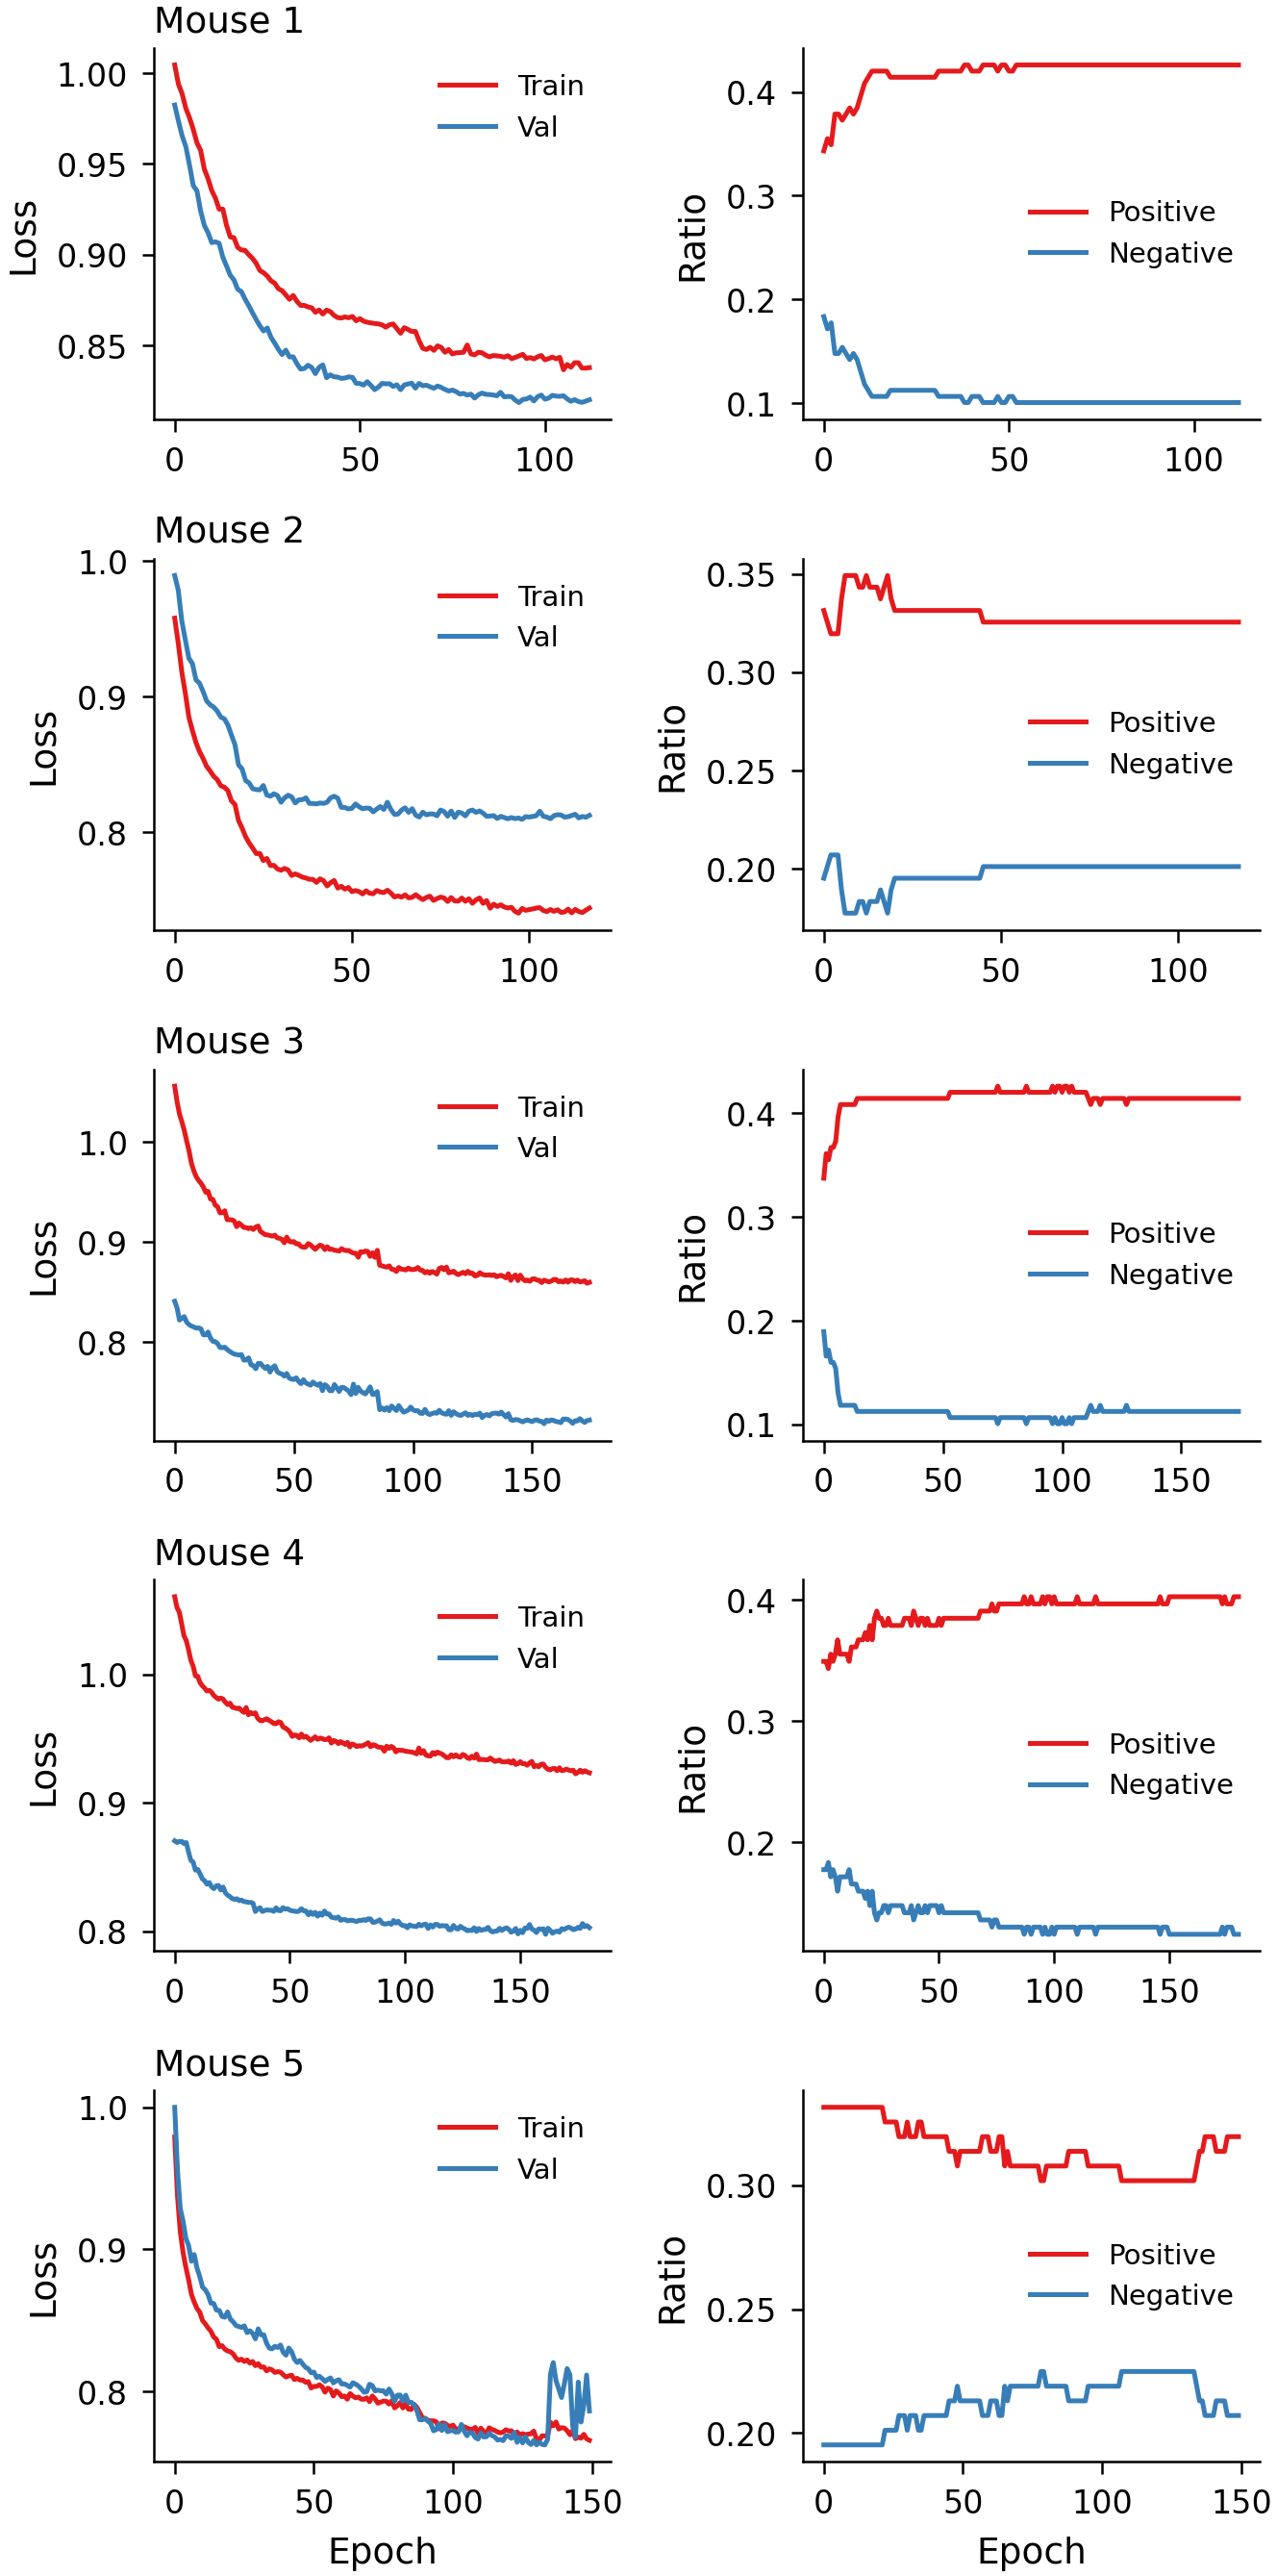

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.minor.width": 0.4,
    "ytick.minor.width": 0.4,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "figure.dpi": 300,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "legend.frameon": False,
    "legend.fontsize": 7,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
})

num_mice = 5
fig, axes = plt.subplots(num_mice, 2, figsize=(4.5, 1.8 * num_mice))

for i in range(num_mice):
    save_dir = f"./result_new/mouse_{i}/stage_0/"
    train_path = os.path.join(save_dir, "train_losses.npy")
    val_path = os.path.join(save_dir, "val_losses.npy")
    epoch_graphs_path = os.path.join(save_dir, "epoch_avg_graphs.npy")

    if not (os.path.exists(train_path) and os.path.exists(val_path) and os.path.exists(epoch_graphs_path)):
        if num_mice > 1:
            axes[i, 0].set_visible(False)
            axes[i, 1].set_visible(False)
        else:
            axes[0].set_visible(False)
            axes[1].set_visible(False)
        continue

    train_losses = np.load(train_path)
    val_losses = np.load(val_path)
    epoch_graphs = np.load(epoch_graphs_path)
    E, N, _ = epoch_graphs.shape

    if len(train_losses) < E or len(val_losses) < E:
        raise ValueError(f"Mouse {i}: loss arrays shorter than graph epochs ({len(train_losses)}, {len(val_losses)} < {E})")
    
    train_losses = train_losses[:E]
    val_losses = val_losses[:E]

    pos_epoch = np.sum(epoch_graphs > 0, axis=(1,2)) / (N*N)
    neg_epoch = np.sum(epoch_graphs < 0, axis=(1,2)) / (N*N)
    epochs = np.arange(E)

    ax = axes[i, 0]
    ax.plot(epochs, train_losses, color='#E41A1C', linewidth=1.2, label='Train')
    ax.plot(epochs, val_losses, color='#377EB8', linewidth=1.2, label='Val')
    ax.set_ylabel('Loss')
    ax.set_title(f'Mouse {i+1}', loc='left', fontsize=9, pad=4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=8)
    ax.legend()

    ax = axes[i, 1]
    ax.plot(epochs, pos_epoch, color='#E41A1C', linewidth=1.2, label='Positive')
    ax.plot(epochs, neg_epoch, color='#377EB8', linewidth=1.2, label='Negative')
    ax.set_ylabel('Ratio')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=8)
    ax.legend()

    if i == num_mice - 1:
        axes[i, 0].set_xlabel('Epoch')
        axes[i, 1].set_xlabel('Epoch')

plt.tight_layout(pad=0.5, h_pad=1.2, w_pad=1.0)
fig_path = "./result_new/all_mice_individual_metrics.png"
plt.savefig(fig_path, dpi=600, bbox_inches='tight', facecolor='white')
plt.show()